# Detecting AI-generated faces in KYC onboarding

**UofT SCS 3546 Deep Learning, term project.** Team: [Names]

Banks and payment companies verify new customers remotely with a selfie or ID photo (KYC, "know your customer").
Generative models such as StyleGAN can now produce photorealistic faces of people who don't exist, which lets
fraudsters open accounts under synthetic identities. This project trains and evaluates deep learning models that
look at a face photo and output **the probability that it is AI-generated**.

**What this notebook covers**

1. Setup
2. Data: the dataset, splits, sample images and preprocessing
3. Real-world photo damage (degradations)
4. Models
5. Training method
6. Experiments E1–E7: training (or loading saved results)
7. Results comparison
8. Live check: re-scoring the saved models inside this notebook
9. Robustness to damaged photos
10. Explainability with Grad-CAM
11. Choosing a decision threshold for KYC (FAR vs. FRR)
12. Final test-set evaluation
13. Conclusions and limitations
14. How to reproduce

Appendix: complete source code

**How to run it.** Training all experiments takes about 20 hours on a laptop GPU (Apple M5), so by default this
notebook **loads the saved results** of those runs (`outputs/`, or `results/` in the repo) instead of retraining.
All the code is still here: set `RUN_TRAINING = True` in Section 1 to retrain everything from scratch. Every other
section (data preparation, model building, scoring the saved models, robustness demo, Grad-CAM, thresholds) runs
live and takes about 5 minutes in total.

The reusable code lives in the package `src/deepfake_kyc/`. Key functions are printed inline with
`inspect.getsource`, so this notebook shows the actual code that produced the results.

## 1. Setup

In [1]:
import inspect
import json
import os
import random
import sys
import time
from pathlib import Path

os.environ["TQDM_DISABLE"] = "1"  # hide per-batch progress bars in the saved notebook
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")

# Run from the project root, whether the notebook is opened from notebooks/ or the root.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image as ShowImage, display
from PIL import Image

from deepfake_kyc import data as dk_data, engine, metrics, models
from deepfake_kyc.config import load_config
from deepfake_kyc.data import IMAGENET_MEAN, IMAGENET_STD, build_loader, build_transform, make_dataset
from deepfake_kyc.degradations import DEGRADATIONS, RandomDegradation
from deepfake_kyc.explain import Explainer
from deepfake_kyc.metrics import compute_metrics
from deepfake_kyc.models import build_model, load_checkpoint
from deepfake_kyc.utils import get_device, seed_everything

# Some project modules switch matplotlib to a file-only backend for scripts; show figures inline here.
%matplotlib inline

# ---- Switches -------------------------------------------------------------------------------
RUN_TRAINING = False      # True = retrain every experiment (~20 h). False = load saved results.
RUN_TEST_EVAL = False     # True = score the held-out TEST set (do this once, at the very end).
LIVE_CHECK_IMAGES = 1000  # validation photos used to re-score each saved model in Section 8.
SEED = 42
# ---------------------------------------------------------------------------------------------

seed_everything(SEED)
DEVICE = get_device()
BASE = load_config("configs/base.yaml")
DATA_ROOT = Path(BASE["data"]["root"])
OUTPUTS, RESULTS = ROOT / "outputs", ROOT / "results"

EXPERIMENTS = {
    "E1": "01_baseline_cnn",
    "E2": "02_effnet_frozen",
    "E3": "03_effnet_finetune",
    "E4": "04_effnet_gradual",
    "E5": "05_resnet50_finetune",
    "E6": "06_effnet_robust",
}
E7_RUNS = {1000: "07_effnet_n1000", 10000: "07_effnet_n10000", 50000: "07_effnet_n50000"}


def run_dir(name):
    # Prefer this machine's outputs/, else the results/ folder committed to the repo.
    return OUTPUTS / name if (OUTPUTS / name / "history.csv").exists() else RESULTS / name


def checkpoint(name):
    path = OUTPUTS / name / "best.pt"
    if not path.exists():
        print(f"Missing {path}: download it from the GitHub release models-v1 (see results/README.md).")
    return path


# Chart style shared by every figure.
COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True,
    "xtick.color": INK_2, "ytick.color": INK_2, "axes.labelcolor": INK_2,
    "axes.titlelocation": "left", "axes.titleweight": "bold",
})
pd.set_option("display.precision", 4)

print(f"Project root: {ROOT.name}   device: {DEVICE}   torch {torch.__version__}")
print(f"RUN_TRAINING={RUN_TRAINING}   RUN_TEST_EVAL={RUN_TEST_EVAL}")

Project root: deepfake-kyc   device: mps   torch 2.15.0
RUN_TRAINING=False   RUN_TEST_EVAL=False


## 2. Data

**Dataset:** [140k Real and Fake Faces](https://www.kaggle.com/datasets/xhlulu/140k-real-and-fake-faces) (Kaggle).
Real faces come from **FFHQ** (Flickr-Faces-HQ, photos of real people). Fake faces were generated by
**StyleGAN**. The dataset ships already split into train / validation / test folders. Download it with `make data`.

**How the splits are used**
- **Train (100k):** the model learns from these.
- **Validation (20k):** choosing settings, early stopping and comparing experiments. All results in Sections 6–11
  are on validation photos.
- **Test (20k):** held out and used **once**, at the end (Section 12), so the final score is unbiased.

**Labels:** `fake = 1` (the class we want to catch, the "positive" class) and `real = 0`.

In [2]:
rows = []
for split, folder in dk_data.SPLIT_DIRS.items():
    for label in ("real", "fake"):
        n = sum(1 for _ in os.scandir(DATA_ROOT / folder / label))
        rows.append({"split": split, "class": label, "images": n})
counts = pd.DataFrame(rows).pivot(index="split", columns="class", values="images").loc[["train", "val", "test"]]
counts["total"] = counts.sum(axis=1)
counts.loc["all"] = counts.sum()
counts

class,fake,real,total
split,,,
train,50000,50000,100000
val,10000,10000,20000
test,10000,10000,20000
all,70000,70000,140000


The classes are perfectly balanced in every split, so accuracy is a fair headline metric and no class weighting is needed.

Folder -> class index: {'fake': 0, 'real': 1}   remapped so that fake = 1, real = 0


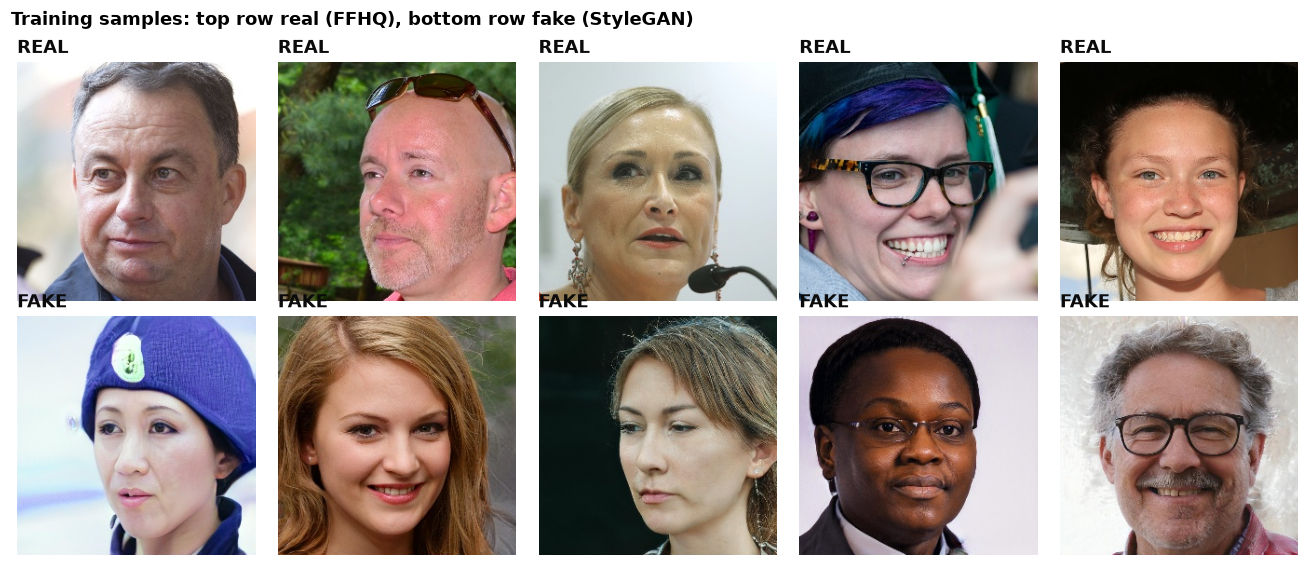

Image sizes in a random sample of 300: {(256, 256): np.int64(300)}


In [3]:
train_ds = make_dataset(DATA_ROOT / "train")
print("Folder -> class index:", train_ds.class_to_idx, "  remapped so that fake = 1, real = 0")

rng = random.Random(SEED)
reals = [p for p, t in train_ds.samples if t == train_ds.class_to_idx["real"]]
fakes = [p for p, t in train_ds.samples if t == train_ds.class_to_idx["fake"]]
sample = [(p, "real") for p in rng.sample(reals, 5)] + [(p, "fake") for p in rng.sample(fakes, 5)]

fig, axes = plt.subplots(2, 5, figsize=(12, 5.2))
for ax, (path, label) in zip(axes.flat, sample):
    ax.imshow(Image.open(path)); ax.set_title(label.upper(), color=INK, fontweight="bold"); ax.axis("off")
fig.suptitle("Training samples: top row real (FFHQ), bottom row fake (StyleGAN)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

sizes = pd.Series([Image.open(p).size for p in rng.sample(reals + fakes, 300)]).value_counts()
print("Image sizes in a random sample of 300:", dict(sizes))

The fakes are very convincing to a human eye. Typical StyleGAN giveaways are subtle: odd teeth or earrings,
smeared backgrounds, hair that blends into the background, and unnaturally smooth skin texture.

### Preprocessing
Every image goes through `build_transform` before reaching the model:
- **Evaluation (validation/test):** resize to 224×224, convert to a tensor, normalise with the ImageNet mean/std
  (the pretrained models expect inputs scaled this way).
- **Training:** a random crop (80–100% of the image, resized to 224), random horizontal flip and slight colour
  jitter. These **augmentations** show the model a slightly different version of each photo every epoch, which
  reduces overfitting.
- **E6 only:** with 50% probability, one random real-world degradation (Section 3) is applied first.

In [4]:
print(inspect.getsource(build_transform))
print("Training transform:\n", build_transform(224, train=True))
print("\nEvaluation transform:\n", build_transform(224, train=False))

def build_transform(
    image_size: int,
    train: bool = False,
    standard: bool = True,
    degradation: bool = False,
    degradation_prob: float = 0.5,
    eval_degradation: Degradation | None = None,
) -> transforms.Compose:
    steps = []
    if eval_degradation is not None:
        steps.append(eval_degradation)
    if train and degradation:
        steps.append(RandomDegradation(p=degradation_prob))
    if train and standard:
        steps += [
            transforms.RandomResizedCrop(image_size, scale=(0.8, 1.0)),
            transforms.RandomHorizontalFlip(),
            transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
        ]
    else:
        steps.append(transforms.Resize((image_size, image_size)))
    steps += [transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]
    return transforms.Compose(steps)

Training transform:
 Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.8, 1.0), ratio=(0.75, 1.3333), interpolation=bil

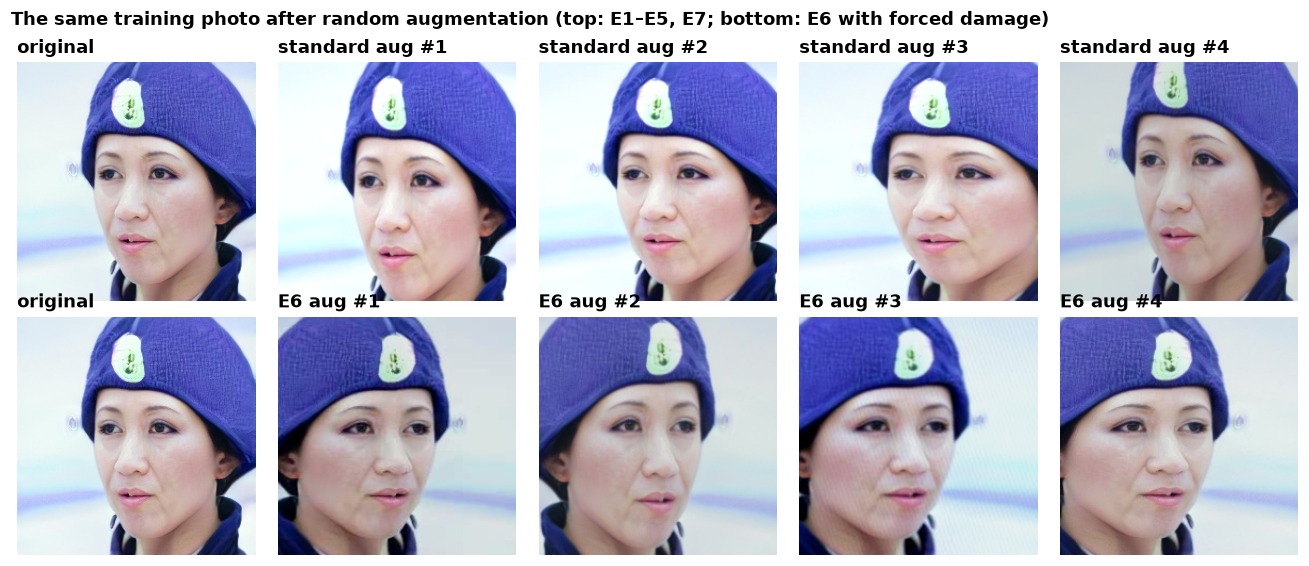

In [5]:
def to_image(tensor):
    # Undo the ImageNet normalisation so a tensor can be displayed.
    x = tensor.permute(1, 2, 0).numpy() * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
    return np.clip(x, 0, 1)

face = Image.open(sample[5][0]).convert("RGB")
train_tf, robust_tf = build_transform(224, train=True), build_transform(224, train=True, degradation=True, degradation_prob=1.0)
fig, axes = plt.subplots(2, 5, figsize=(12, 5.2))
axes[0, 0].imshow(face); axes[0, 0].set_title("original")
axes[1, 0].imshow(face); axes[1, 0].set_title("original")
for i in range(1, 5):
    axes[0, i].imshow(to_image(train_tf(face))); axes[0, i].set_title(f"standard aug #{i}")
    axes[1, i].imshow(to_image(robust_tf(face))); axes[1, i].set_title(f"E6 aug #{i}")
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("The same training photo after random augmentation (top: E1–E5, E7; bottom: E6 with forced damage)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

## 3. Real-world photo damage (degradations)

KYC uploads are rarely clean: customers send compressed, blurry, low-resolution phone photos, and some
fraudsters photograph a screen showing the fake face. `degradations.py` simulates five kinds of damage at
severities 1 (mild) to 5 (severe). They are used twice:
- to **test** robustness (Section 9), and
- to **train** a more robust model (E6).

In [6]:
levels = pd.DataFrame({name: cls.levels for name, cls in DEGRADATIONS.items()}, index=[f"sev {i}" for i in range(1, 6)]).T
levels.index = ["JPEG quality", "blur radius (px)", "downscale factor", "noise std (0-255)", "moire strength"]
display(levels)
print(inspect.getsource(DEGRADATIONS["screen"]))

,sev 1,sev 2,sev 3,sev 4,sev 5
JPEG quality,90.00,70.00,50.00,30.00,10.00
blur radius (px),0.50,1.00,1.50,2.50,4.00
downscale factor,0.75,0.50,0.35,0.25,0.15
noise std (0-255),5.00,10.00,20.00,30.00,45.00
moire strength,0.03,0.06,0.09,0.12,0.15


class ScreenCapture(Degradation):
    """Photo of a screen: moire stripes, blue colour cast, slight blur and compression.

    Param: strength of the moire pattern.
    """

    levels = (0.03, 0.06, 0.09, 0.12, 0.15)

    def apply(self, img):
        arr = np.asarray(img, dtype=np.float32) / 255.0
        h, w = arr.shape[:2]
        yy, xx = np.mgrid[0:h, 0:w]
        angle, period = 0.3, 4.0
        stripes = np.sin(2 * np.pi * (xx * np.cos(angle) + yy * np.sin(angle)) / period)
        arr = arr * (1 + self.param * stripes[..., None])
        arr = (arr * np.array([1.0, 1.02, 1.06])) ** 1.1
        out = Image.fromarray((np.clip(arr, 0, 1) * 255).astype(np.uint8))
        return _jpeg(out.filter(ImageFilter.GaussianBlur(0.8)), 75)



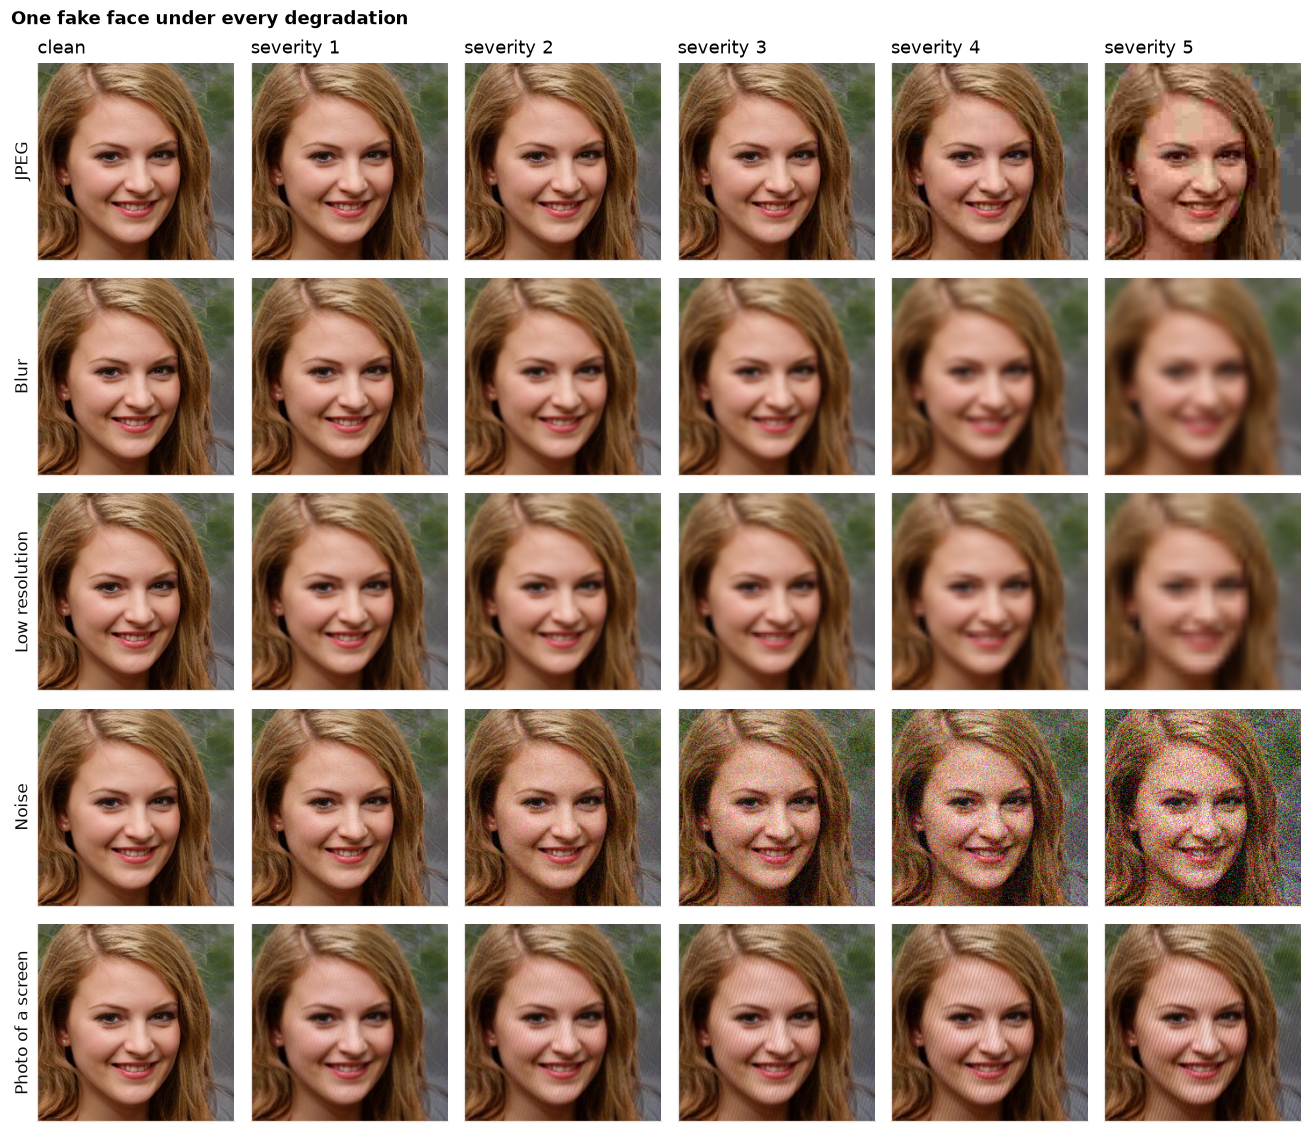

In [7]:
random.seed(SEED); np.random.seed(SEED)
face = Image.open(sample[6][0]).convert("RGB").resize((224, 224))
titles = {"jpeg": "JPEG", "blur": "Blur", "downscale": "Low resolution", "noise": "Noise", "screen": "Photo of a screen"}
fig, axes = plt.subplots(5, 6, figsize=(12, 10.5))
for r, (name, cls) in enumerate(DEGRADATIONS.items()):
    axes[r, 0].imshow(face); axes[r, 0].set_ylabel(titles[name], fontsize=11, color=INK)
    for s in range(1, 6):
        axes[r, s].imshow(cls(s)(face))
    for c, ax in enumerate(axes[r]):
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        if r == 0:
            ax.set_title("clean" if c == 0 else f"severity {c}", fontweight="normal")
fig.suptitle("One fake face under every degradation", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

## 4. Models

All models take a 224×224 RGB image and output **one number (a logit)**. `sigmoid(logit)` = P(fake).

| Model | Idea | Weights |
|---|---|---|
| **SimpleCNN** (E1) | Our own baseline: 4 convolution blocks (conv → batch-norm → ReLU → max-pool), global average pooling, a dropout + linear head. Trained **from scratch**. | ~0.4 M |
| **EfficientNet-B0** (E2–E4, E6, E7) | A compact, accurate CNN built from depthwise-separable convolution blocks, **pretrained on ImageNet** (1.2 M photos). | ~4.0 M |
| **ResNet-50** (E5) | A deeper classic CNN with residual (skip) connections, pretrained on ImageNet. | ~23.5 M |

For the pretrained models, the original 1000-class ImageNet head is replaced by a new **classifier head** with a
single output (via `timm`). Everything before the head is the **backbone**, which turns the photo into a feature
vector (1280 numbers for EfficientNet-B0, 2048 for ResNet-50).

In [8]:
print(inspect.getsource(models.SimpleCNN))
print(inspect.getsource(models.build_model))

class SimpleCNN(nn.Module):
    """Small baseline trained from scratch: four conv blocks, global pooling, linear head."""

    def __init__(self, dropout: float = 0.2):
        super().__init__()

        def block(c_in, c_out):
            return nn.Sequential(
                nn.Conv2d(c_in, c_out, 3, padding=1, bias=False),
                nn.BatchNorm2d(c_out),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
            )

        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(dropout), nn.Linear(256, 1))

    def forward(self, x):
        return self.head(self.pool(self.features(x)))

def build_model(name: str, pretrained: bool = True, dropout: float = 0.2) -> nn.Module:
    """``simple_cnn`` or any timm model name (e.g. ``efficientnet_b0``, ``resnet50``, ``vit_small_patch16_224``)."""
    if name == "simple_cnn

In [9]:
rows = []
for name in ["simple_cnn", "efficientnet_b0", "resnet50"]:
    m = build_model(name, pretrained=False)
    head = models.head_module(m)
    n_all = sum(p.numel() for p in m.parameters())
    n_head = sum(p.numel() for p in head.parameters())
    with torch.no_grad():
        out = m.eval()(torch.zeros(1, 3, 224, 224))
    rows.append({"model": name, "parameters": f"{n_all:,}", "head parameters": f"{n_head:,}",
                 "classifier head": str(head).replace("\n", " "), "output shape": tuple(out.shape)})
pd.DataFrame(rows).set_index("model")

,parameters,head parameters,classifier head,output shape
model,,,,
simple_cnn,"389,153",257,"Sequential( (0): Flatten(start_dim=1, end_di...","(1, 1)"
efficientnet_b0,"4,008,829","1,281","Linear(in_features=1280, out_features=1, bias=...","(1, 1)"
resnet50,"23,510,081","2,049","Linear(in_features=2048, out_features=1, bias=...","(1, 1)"


## 5. Training method

Every experiment is a small YAML file in `configs/experiments/` that overrides `configs/base.yaml`. The shared
settings:

- **Loss:** binary cross-entropy on the logit (`BCEWithLogitsLoss`). It punishes confident mistakes most.
- **Optimiser:** AdamW (Adam with decoupled weight decay 1e-4), mini-batches of 64 images.
- **Two learning rates:** the new head learns at the full rate (3e-4), the pretrained backbone at 10× less
  (`backbone_lr_mult: 0.1`), so fine-tuning adjusts the ImageNet features gently instead of overwriting them.
- **Schedule:** linear warm-up for the first epoch, then cosine decay to zero.
- **Regularisation:** dropout 0.2 before the head, weight decay, data augmentation.
- **Model selection:** after each epoch the model is scored on the validation set; the epoch with the **lowest
  validation loss** is saved as `best.pt`. Training stops early if validation loss doesn't improve for 2 epochs.
- **Reproducibility:** fixed seed 42 for Python, NumPy and PyTorch, and for every data subset.

In [10]:
print(inspect.getsource(models.split_parameters))
print(inspect.getsource(engine.warmup_cosine))
print(inspect.getsource(engine.train_one_epoch))
print(inspect.getsource(engine.predict))

def split_parameters(model: nn.Module) -> tuple[list, list]:
    """Return (backbone_params, head_params) so they can get different learning rates."""
    head_ids = {id(p) for p in head_module(model).parameters()}
    backbone = [p for p in model.parameters() if id(p) not in head_ids]
    head = [p for p in model.parameters() if id(p) in head_ids]
    return backbone, head

def warmup_cosine(warmup_steps: int, total_steps: int):
    """LR multiplier: linear warm-up, then cosine decay to zero (for ``LambdaLR``)."""

    def factor(step: int) -> float:
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1 + math.cos(math.pi * min(progress, 1.0)))

    return factor

def train_one_epoch(model, loader: DataLoader, criterion, optimizer, scheduler, device) -> float:
    model.train()
    total_loss, seen = 0.0, 0
    for images, labels in tqdm(loader, desc="train", le

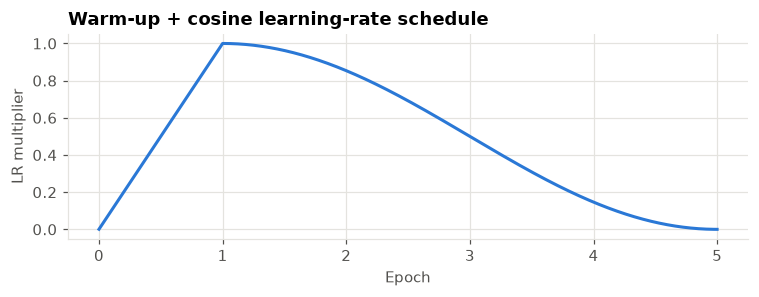

In [11]:
# Learning-rate multiplier over E3's 5 epochs (1,563 steps per epoch).
steps = 1563
f = engine.warmup_cosine(1 * steps, 5 * steps)
x = np.arange(5 * steps)
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.plot(x / steps, [f(i) for i in x], color=COLOURS[0], linewidth=2)
ax.set_xlabel("Epoch"); ax.set_ylabel("LR multiplier"); ax.set_title("Warm-up + cosine learning-rate schedule")
plt.tight_layout(); plt.show()

### Metrics
Besides accuracy, F1 and ROC-AUC, we report the two error rates used in identity verification:
- **FAR (False Acceptance Rate):** share of **fake** faces accepted as real. This is the security risk (a fraudster gets an account).
- **FRR (False Rejection Rate):** share of **real** customers flagged as fake. This is the customer-experience cost.

In [12]:
print(inspect.getsource(compute_metrics))

def compute_metrics(labels, probs, threshold: float = 0.5) -> dict[str, float]:
    """Standard classification metrics plus the two identity-verification error rates.

    FAR (False Acceptance Rate): share of fake faces the model lets through as real.
    FRR (False Rejection Rate): share of real customers the model wrongly flags as fake.
    """
    labels = np.asarray(labels).astype(int)
    probs = np.asarray(probs, dtype=float)
    preds = (probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, preds, labels=[0, 1]).ravel()
    both_classes = len(np.unique(labels)) == 2
    return {
        "accuracy": float(accuracy_score(labels, preds)),
        "precision": float(precision_score(labels, preds, zero_division=0)),
        "recall": float(recall_score(labels, preds, zero_division=0)),
        "f1": float(f1_score(labels, preds, zero_division=0)),
        "roc_auc": float(roc_auc_score(labels, probs)) if both_classes else float("nan"),
        "far": float(fn

## 6. Experiments

| Exp | Question | Model | What changes vs. E3 |
|---|---|---|---|
| E1 | How good is a CNN trained from scratch? (**baseline**) | SimpleCNN | no pretraining, 10 epochs, LR 1e-3 |
| E2 | Are pretrained features enough on their own? | EfficientNet-B0 | backbone **frozen**, only the head trains |
| E3 | Does full fine-tuning help? (**main model**) | EfficientNet-B0 | — |
| E4 | Does gradual unfreezing help? | EfficientNet-B0 | backbone frozen for epoch 1, then unfrozen |
| E5 | Does a bigger architecture help? | ResNet-50 | different backbone, batch 32 |
| E6 | Does training on damaged photos improve robustness? | EfficientNet-B0 | 50% of training photos randomly degraded |
| E7 | How much training data do we need? | EfficientNet-B0 | 1k / 10k / 50k training photos |

The exact settings of each run, as loaded from its config file:

In [13]:
def flat(cfg):
    return {
        "model": cfg["model"]["name"], "pretrained": cfg["model"]["pretrained"],
        "epochs": cfg["train"]["epochs"], "lr": cfg["train"]["lr"],
        "backbone_lr_mult": cfg["train"]["backbone_lr_mult"],
        "frozen_epochs": cfg["train"]["freeze_backbone_epochs"], "warmup": cfg["train"]["warmup_epochs"],
        "batch": cfg["data"]["batch_size"], "damage_aug": cfg["augment"]["degradation"],
        "train_images": cfg["data"]["train_subset"] or 100_000,
    }

configs = {exp: load_config(f"configs/experiments/{name}.yaml") for exp, name in EXPERIMENTS.items()}
for n, name in E7_RUNS.items():
    configs[f"E7 ({n // 1000}k)"] = load_config("configs/experiments/03_effnet_finetune.yaml",
                                                [f"data.train_subset={n}", f"experiment_name={name}"])
pd.DataFrame({k: flat(v) for k, v in configs.items()}).T

,model,pretrained,epochs,lr,backbone_lr_mult,frozen_epochs,warmup,batch,damage_aug,train_images
E1,simple_cnn,False,10,0.001,1.0,0,1,64,False,100000
E2,efficientnet_b0,True,5,0.001,0.1,999,1,64,False,100000
E3,efficientnet_b0,True,5,0.0003,0.1,0,1,64,False,100000
E4,efficientnet_b0,True,5,0.0003,0.1,1,0,64,False,100000
E5,resnet50,True,5,0.0003,0.1,0,1,32,False,100000
E6,efficientnet_b0,True,5,0.0003,0.1,0,1,64,True,100000
E7 (1k),efficientnet_b0,True,5,0.0003,0.1,0,1,64,False,1000
E7 (10k),efficientnet_b0,True,5,0.0003,0.1,0,1,64,False,10000
E7 (50k),efficientnet_b0,True,5,0.0003,0.1,0,1,64,False,50000


### Training (or loading the saved runs)
This is the cell that trains every experiment. `train.main` is the same entry point as `make train`. It writes
`best.pt`, `config.yaml`, `history.csv` and `summary.json` to `outputs/<experiment>/`.

With `RUN_TRAINING = False` it skips training and loads those saved files. Total training time on an Apple M5
laptop was about 20 hours (see the time column below).

In [14]:
from deepfake_kyc import train

runs = {exp: name for exp, name in EXPERIMENTS.items()} | {f"E7 ({n // 1000}k)": name for n, name in E7_RUNS.items()}

if RUN_TRAINING:
    for exp, name in runs.items():
        if exp.startswith("E7"):
            n = int(name.split("_n")[-1])
            train.main(["--config", "configs/experiments/03_effnet_finetune.yaml",
                        "--set", f"data.train_subset={n}", f"experiment_name={name}"])
        else:
            train.main(["--config", f"configs/experiments/{name}.yaml"])

histories = {exp: pd.read_csv(run_dir(name) / "history.csv") for exp, name in runs.items()}
for exp, name in runs.items():
    print(f"{exp:<9} loaded {len(histories[exp])} epochs from {run_dir(name).relative_to(ROOT)}/history.csv")

E1        loaded 10 epochs from outputs/01_baseline_cnn/history.csv
E2        loaded 5 epochs from outputs/02_effnet_frozen/history.csv
E3        loaded 5 epochs from outputs/03_effnet_finetune/history.csv
E4        loaded 4 epochs from outputs/04_effnet_gradual/history.csv
E5        loaded 5 epochs from outputs/05_resnet50_finetune/history.csv
E6        loaded 5 epochs from outputs/06_effnet_robust/history.csv
E7 (1k)   loaded 5 epochs from outputs/07_effnet_n1000/history.csv
E7 (10k)  loaded 5 epochs from outputs/07_effnet_n10000/history.csv
E7 (50k)  loaded 5 epochs from outputs/07_effnet_n50000/history.csv


**Note on E4.** E4 was stopped after 4 of its 5 epochs: the laptop ran short of memory and each epoch was taking
longer than the last. It trailed E3 at every epoch, so a 5th epoch wouldn't change the conclusion. Its best
checkpoint (epoch 4) is used.

**Note on time.** Some runs (E6, E4, and the 1k run of E7) took longer than expected because the laptop was
swapping memory to disk, not because of the experiment itself. Typical speed was ~25 min per epoch for
EfficientNet-B0 and ~49 min for ResNet-50.

In [15]:
print("Example: E3's per-epoch history")
histories["E3"]

Example: E3's per-epoch history


,epoch,backbone_frozen,train_loss,val_loss,val_accuracy,val_f1,val_roc_auc,seconds
0,1,False,1.3296,0.2694,0.9242,0.9214,0.9805,1468.5
1,2,False,0.2307,0.0823,0.9744,0.9739,0.9978,1437.6
2,3,False,0.0942,0.0382,0.9866,0.9865,0.9993,1630.8
3,4,False,0.0611,0.0306,0.9885,0.9884,0.9996,1493.5
4,5,False,0.0517,0.0305,0.9889,0.9888,0.9996,1522.2


## 7. Results comparison (validation set, 20,000 images)

In [16]:
labels = {
    "E1": "E1 SimpleCNN (scratch)", "E2": "E2 EffNet-B0 frozen", "E3": "E3 EffNet-B0 fine-tune",
    "E4": "E4 EffNet-B0 gradual", "E5": "E5 ResNet-50 fine-tune", "E6": "E6 EffNet-B0 robust",
}
rows = []
for exp, h in histories.items():
    best = h.loc[h["val_loss"].idxmin()]
    rows.append({"experiment": exp, "best epoch": f"{int(best['epoch'])} / {len(h)}",
                 "val accuracy": best["val_accuracy"], "val F1": best["val_f1"], "val ROC-AUC": best["val_roc_auc"],
                 "val loss": best["val_loss"], "train minutes": round(h["seconds"].sum() / 60)})
summary = pd.DataFrame(rows).set_index("experiment")
summary.style.format({"val accuracy": "{:.2%}", "val F1": "{:.4f}", "val ROC-AUC": "{:.4f}", "val loss": "{:.4f}"})

,best epoch,val accuracy,val F1,val ROC-AUC,val loss,train minutes
experiment,,,,,,
E1,10 / 10,97.52%,0.9751,0.9974,0.0678,105
E2,5 / 5,77.68%,0.7758,0.8606,0.5855,34
E3,5 / 5,98.89%,0.9888,0.9996,0.0305,126
E4,4 / 4,98.21%,0.9819,0.9989,0.0539,203
E5,5 / 5,99.17%,0.9917,0.9997,0.0236,247
E6,5 / 5,98.50%,0.9848,0.9992,0.0421,211
E7 (1k),5 / 5,65.77%,0.6824,0.7200,1.5244,716
E7 (10k),5 / 5,86.72%,0.8639,0.9425,0.4768,21
E7 (50k),5 / 5,97.22%,0.9721,0.9969,0.0835,70


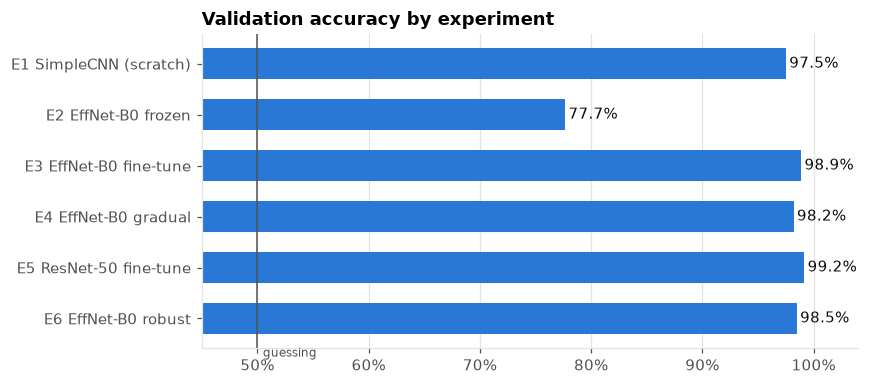

In [17]:
main = summary.loc[list(EXPERIMENTS)].iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.barh([labels[e] for e in main.index], main["val accuracy"], color=COLOURS[0], height=0.6)
for bar, v in zip(bars, main["val accuracy"]):
    ax.text(v + 0.003, bar.get_y() + bar.get_height() / 2, f"{v:.1%}", va="center", color=INK)
ax.axvline(0.5, color=INK_2, linewidth=1); ax.text(0.505, -0.75, "guessing", color=INK_2, fontsize=8)
ax.set_xlim(0.45, 1.04); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax.set_title("Validation accuracy by experiment")
plt.tight_layout(); plt.show()

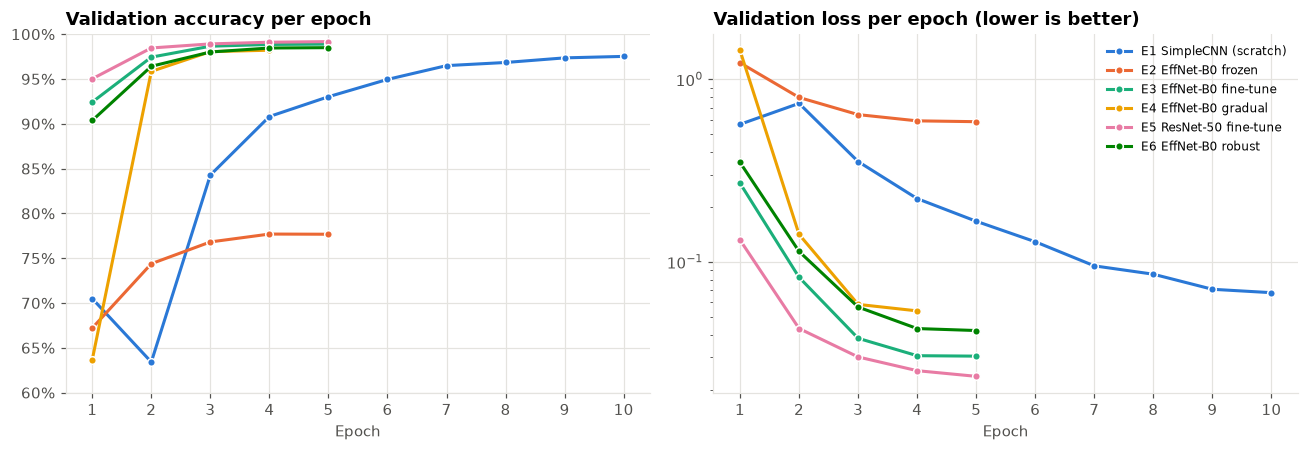

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for i, exp in enumerate(EXPERIMENTS):
    h = histories[exp]
    for ax, col in zip(axes, ["val_accuracy", "val_loss"]):
        ax.plot(h["epoch"], h[col], color=COLOURS[i], marker="o", markersize=5, linewidth=2,
                markeredgecolor="white", label=labels[exp])
axes[0].set_title("Validation accuracy per epoch"); axes[0].set_ylim(0.6, 1.0)
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
axes[1].set_title("Validation loss per epoch (lower is better)"); axes[1].set_yscale("log")
for ax in axes:
    ax.set_xlabel("Epoch"); ax.set_xticks(range(1, 11))
axes[1].legend(frameon=False, fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

**What the comparison shows**
- **Transfer learning works, but only with fine-tuning.** Frozen ImageNet features (E2) reach only ~78%: features
  learned to recognise cats and cars don't capture the fine texture artefacts StyleGAN leaves. Fine-tuning the
  same network (E3) reaches ~98.9%.
- **The from-scratch baseline is strong** (E1, 97.5%) because these fakes contain consistent low-level artefacts
  that even a small CNN can learn with 100k examples, but it needed 10 epochs and was still improving.
- **Gradual unfreezing (E4) didn't help**: its frozen first epoch (64%) was wasted, and it trailed E3 at every
  later epoch. E3's lower backbone learning rate and warm-up already protect the pretrained weights.
- **A 6× larger model (E5, ResNet-50) adds only ~0.3 points** for ~2× the training time and a 6× larger file.
  EfficientNet-B0 is the better choice for deployment.
- **Robust training (E6) costs ~0.4 points on clean photos** but pays off strongly on damaged ones (Section 9).

### E7: how much training data is needed?

,training images,val accuracy,val ROC-AUC,update steps
0,"1,000",65.77%,0.7200,80
1,"10,000",86.72%,0.9425,785
2,"50,000",97.22%,0.9969,"3,910"
3,"100,000",98.89%,0.9996,"7,815"


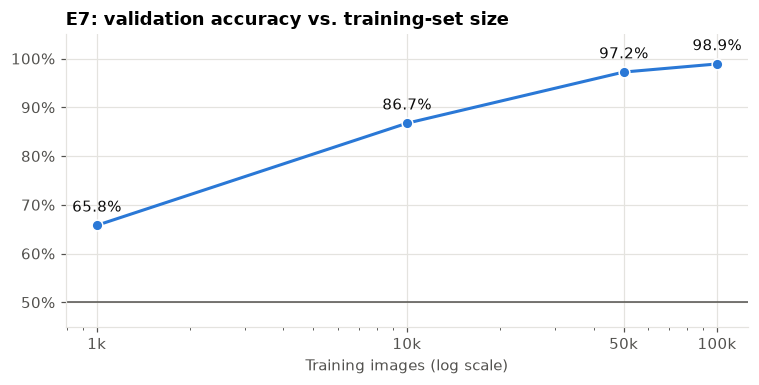

In [19]:
e7 = pd.DataFrame({
    "training images": [1_000, 10_000, 50_000, 100_000],
    "val accuracy": [summary.loc[f"E7 ({k}k)", "val accuracy"] for k in (1, 10, 50)] + [summary.loc["E3", "val accuracy"]],
    "val ROC-AUC": [summary.loc[f"E7 ({k}k)", "val ROC-AUC"] for k in (1, 10, 50)] + [summary.loc["E3", "val ROC-AUC"]],
    "update steps": [5 * int(np.ceil(n / 64)) for n in (1_000, 10_000, 50_000, 100_000)],
})
display(e7.style.format({"val accuracy": "{:.2%}", "val ROC-AUC": "{:.4f}", "training images": "{:,}", "update steps": "{:,}"}))

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(e7["training images"], e7["val accuracy"], color=COLOURS[0], marker="o", markersize=7, linewidth=2,
        markeredgecolor="white")
for n, v in zip(e7["training images"], e7["val accuracy"]):
    ax.annotate(f"{v:.1%}", (n, v), textcoords="offset points", xytext=(0, 9), ha="center", color=INK)
ax.set_xscale("log"); ax.set_xticks(e7["training images"], ["1k", "10k", "50k", "100k"])
ax.axhline(0.5, color=INK_2, linewidth=1)
ax.set_ylim(0.45, 1.05); ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Training images (log scale)"); ax.set_title("E7: validation accuracy vs. training-set size")
plt.tight_layout(); plt.show()

Accuracy climbs steeply up to 50k images and then flattens (+1.7 points from 50k to 100k). For a bank, a detector
like this needs **tens of thousands** of labelled examples, not a few thousand.

*Caveat:* every run used 5 epochs, so smaller sets also got far fewer update steps (80 vs. 7,815). The small runs
are partly **undertrained**, not only short of data (the 1k run was still improving when it stopped).

## 8. Live check: re-scoring the saved models

The numbers above were loaded from files. To show they are real, this section loads each saved `best.pt` and
scores a fresh random sample of validation photos **inside this notebook**. The sample accuracy should be close
to the full-validation number (a 1,000-photo sample is accurate to roughly ±1 point).

In [20]:
def score(name, n_images=LIVE_CHECK_IMAGES, degradation=None):
    model, cfg = load_checkpoint(checkpoint(name), DEVICE)
    cfg["data"].update(val_subset=n_images, num_workers=0)
    loader = build_loader(cfg, "val", eval_degradation=degradation)
    probs, labels_, _ = engine.predict(model, loader, DEVICE)
    return probs, labels_

rows, live_probs = [], {}
for exp, name in EXPERIMENTS.items():
    start = time.time()
    probs, y = score(name)
    live_probs[exp] = (probs, y)
    m = compute_metrics(y, probs)
    rows.append({"experiment": exp, "reported val accuracy (20k)": summary.loc[exp, "val accuracy"],
                 f"live accuracy ({len(y):,} photos)": m["accuracy"], "live ROC-AUC": m["roc_auc"],
                 "FAR": m["far"], "FRR": m["frr"], "seconds": round(time.time() - start, 1)})
live = pd.DataFrame(rows).set_index("experiment")
live.style.format({c: "{:.2%}" for c in live.columns if "accuracy" in c or c in ("FAR", "FRR")} | {"live ROC-AUC": "{:.4f}"})

,reported val accuracy (20k),"live accuracy (1,000 photos)",live ROC-AUC,FAR,FRR,seconds
experiment,,,,,,
E1,97.52%,97.80%,0.9983,2.61%,1.79%,4.700000
E2,77.68%,74.30%,0.8257,26.91%,24.50%,5.500000
E3,98.89%,98.70%,0.9997,2.41%,0.20%,4.900000
E4,98.21%,98.00%,0.9984,3.01%,1.00%,4.700000
E5,99.17%,99.30%,0.9999,1.00%,0.40%,10.000000
E6,98.50%,98.30%,0.9989,2.81%,0.60%,5.200000


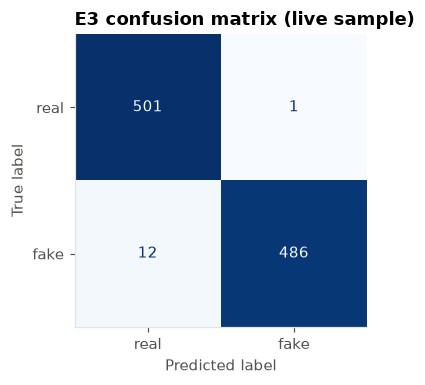

In [21]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

probs, y = live_probs["E3"]
fig, ax = plt.subplots(figsize=(4, 3.6))
ConfusionMatrixDisplay(confusion_matrix(y, probs >= 0.5), display_labels=["real", "fake"]).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.grid(False); ax.set_title("E3 confusion matrix (live sample)")
plt.tight_layout(); plt.show()

## 9. Robustness to damaged photos (E3 vs. E6)

Each saved model was scored on the same 2,000 validation photos (seed 42) under all 5 degradations × 5 severities
(26 conditions including clean), using:

```bash
python -m deepfake_kyc.evaluate --checkpoint outputs/<exp>/best.pt --split val --degradation all \
    --set data.val_subset=2000 --name val_robustness
```

Those runs take ~20 minutes per model, so the saved CSVs are loaded here, and a small live demo follows.

In [22]:
robust = {}
for exp in ("E3", "E6"):
    df = pd.read_csv(run_dir(EXPERIMENTS[exp]) / "eval_val_robustness.csv")
    robust[exp] = df

table = pd.concat({exp: df.set_index(["condition", "severity"])["accuracy"] for exp, df in robust.items()}, axis=1)
damaged = table.drop(index="clean", level=0)
print(f"Clean accuracy:              E3 {table.loc[('clean', 0), 'E3']:.1%}   E6 {table.loc[('clean', 0), 'E6']:.1%}")
print(f"Average over 25 damaged:     E3 {damaged['E3'].mean():.1%}   E6 {damaged['E6'].mean():.1%}")
print(f"Average at severity 5 only:  E3 {damaged.xs(5, level=1)['E3'].mean():.1%}   E6 {damaged.xs(5, level=1)['E6'].mean():.1%}")
damaged.unstack("severity").style.format("{:.1%}")

Clean accuracy:              E3 98.9%   E6 98.7%
Average over 25 damaged:     E3 71.6%   E6 89.6%
Average at severity 5 only:  E3 54.8%   E6 79.2%


Saved outputs/figures/robustness_val.png


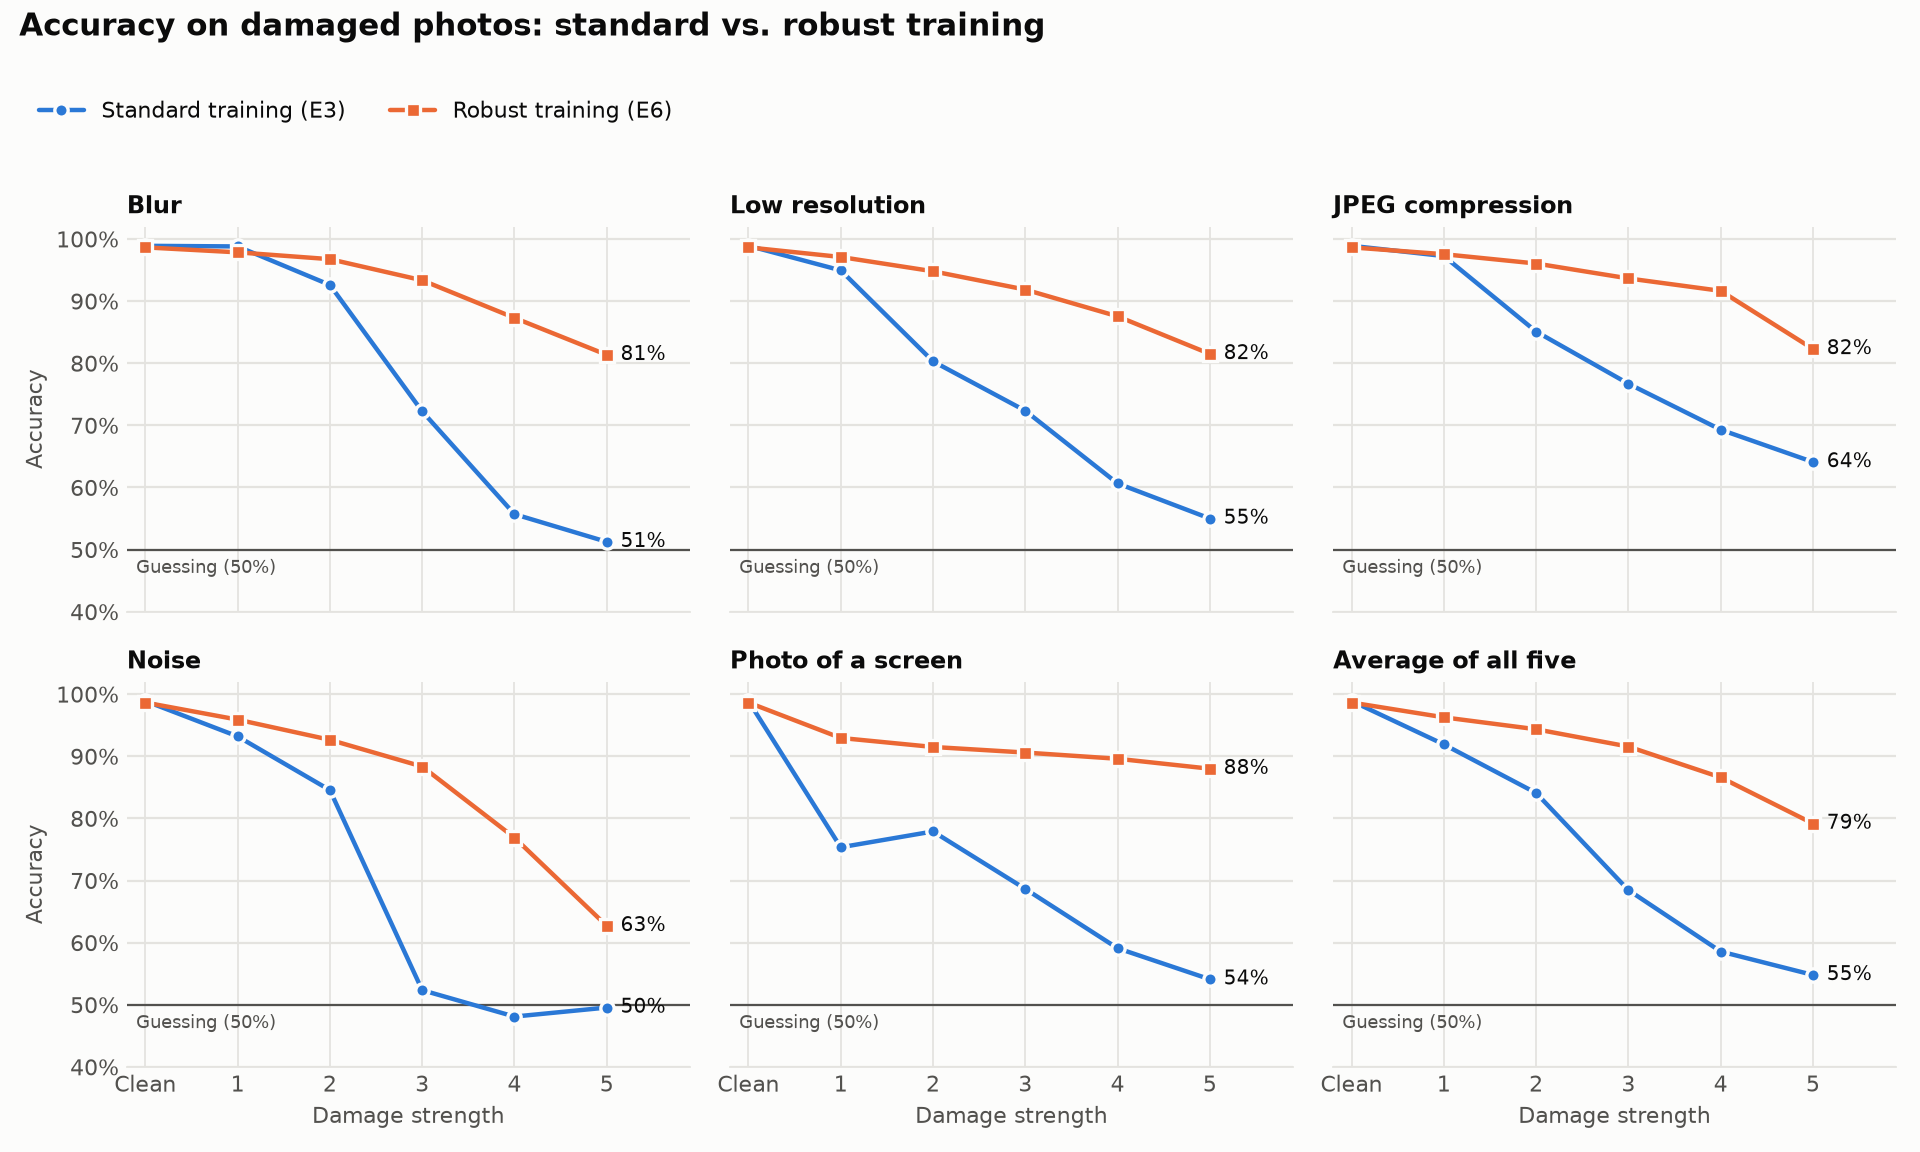

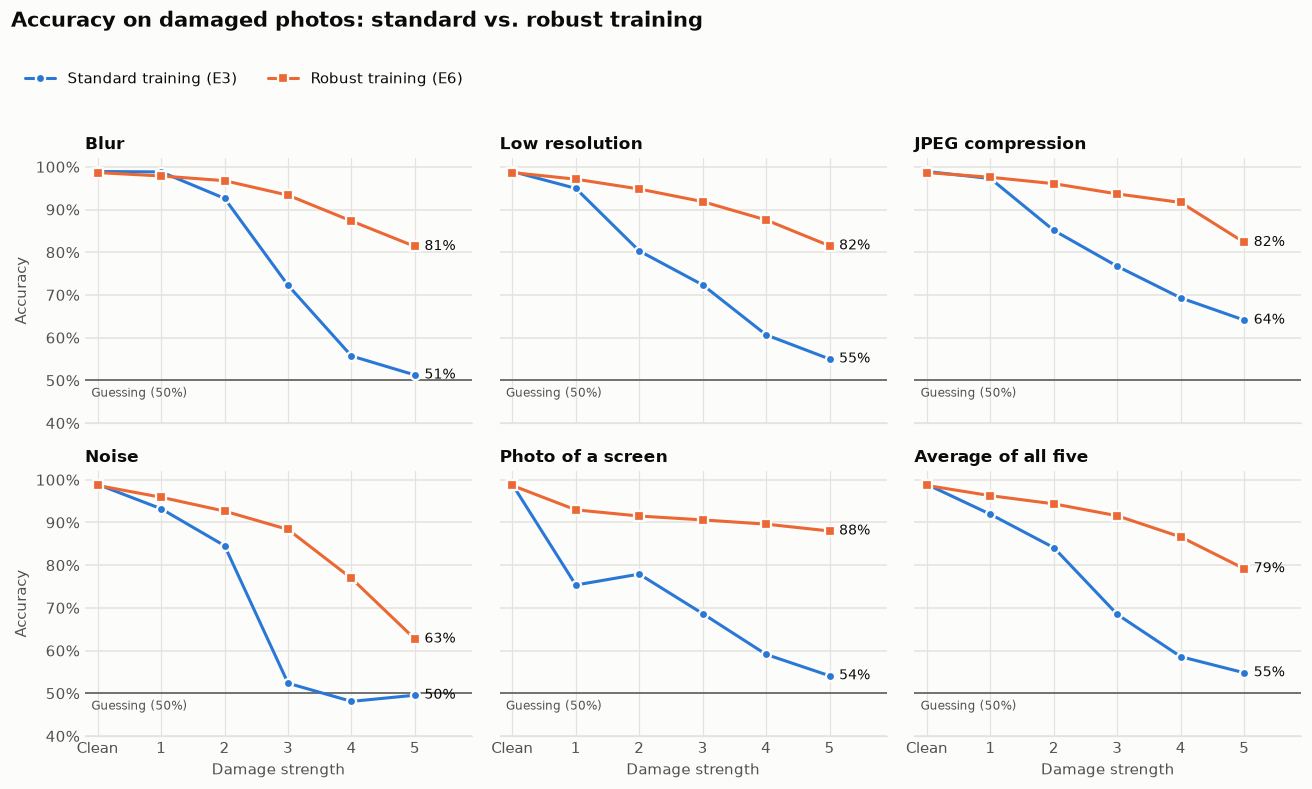

In [23]:
import importlib.util

spec = importlib.util.spec_from_file_location("plot_robustness", ROOT / "scripts" / "plot_robustness.py")
plot_robustness = importlib.util.module_from_spec(spec); spec.loader.exec_module(plot_robustness)
%matplotlib inline

figure_path = Path("outputs/figures/robustness_val.png")  # relative to the project root
plot_robustness.main([
    "--run", f"Standard training (E3)={run_dir(EXPERIMENTS['E3']) / 'eval_val_robustness.csv'}",
    "--run", f"Robust training (E6)={run_dir(EXPERIMENTS['E6']) / 'eval_val_robustness.csv'}",
    "--output", str(figure_path),
])
display(ShowImage(filename=str(figure_path), width=950))

The standard model (E3) collapses towards coin-flip accuracy at heavy blur, noise and low resolution, exactly the
conditions of a cheap phone camera. Training with random damage (E6) keeps accuracy far higher (average over the
25 damaged conditions ~90% vs. ~72%) while losing almost nothing on clean photos.

*Caveat:* E6 was trained with the same 5 damage types it is tested on, so this is an optimistic estimate.
Damage types it never saw would be a harder test.

### Live demo: one fake face, increasingly blurred

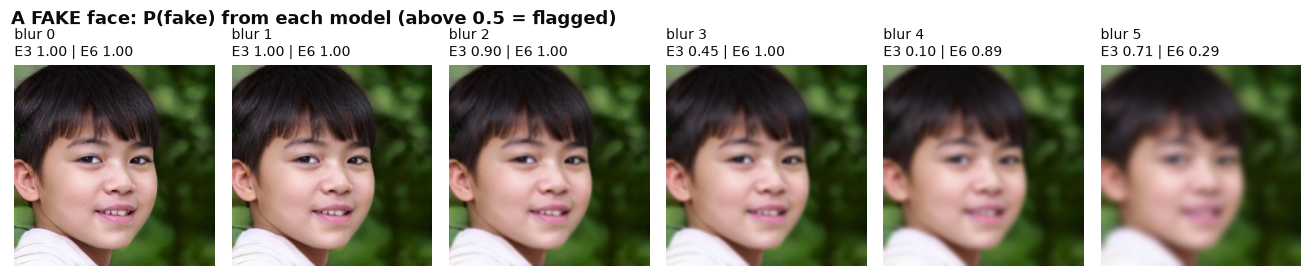

,E3 P(fake),E6 P(fake)
blur severity,,
0,1.000,0.998
1,1.000,1.000
2,0.899,0.997
3,0.455,0.996
4,0.096,0.890
5,0.715,0.291


In [24]:
val_ds = make_dataset(DATA_ROOT / "valid")
fake_path = [p for p, t in val_ds.samples if t == val_ds.class_to_idx["fake"]][7]
face = Image.open(fake_path).convert("RGB")
tf = build_transform(224)
demo_models = {exp: load_checkpoint(checkpoint(EXPERIMENTS[exp]), DEVICE)[0] for exp in ("E3", "E6")}

rows, images = [], []
for s in range(0, 6):
    img = face if s == 0 else DEGRADATIONS["blur"](s)(face)
    images.append(img)
    x = tf(img).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        rows.append({"blur severity": s} | {f"{e} P(fake)": torch.sigmoid(m(x)).item() for e, m in demo_models.items()})

fig, axes = plt.subplots(1, 6, figsize=(12, 2.6))
for ax, img, r in zip(axes, images, rows):
    ax.imshow(img); ax.axis("off")
    ax.set_title(f"blur {r['blur severity']}\nE3 {r['E3 P(fake)']:.2f} | E6 {r['E6 P(fake)']:.2f}", fontsize=9, fontweight="normal")
fig.suptitle("A FAKE face: P(fake) from each model (above 0.5 = flagged)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()
pd.DataFrame(rows).set_index("blur severity").style.format("{:.3f}")

On this photo, E3 loses the fake at blur 3–4 (P(fake) falls below 0.5), while E6 still flags it up to blur 4. At
the most extreme blur (5), E6 misses it and E3's score happens to rise again. A single photo is only an
illustration: the averages over 2,000 photos above are the evidence.

## 10. Explainability with Grad-CAM

Grad-CAM shows **where** in the photo the evidence for "fake" came from. It takes the feature maps of the last
convolutional layer (7×7 for EfficientNet-B0), weights each map by how much it pushed the "fake" score up
(the average gradient), and overlays the result on the photo. Red = strong evidence for "fake".

Because the maps are only 7×7, heatmaps are coarse blobs. Each heatmap is scaled to its own maximum, so on a
confidently *real* photo the few red spots reflect very weak evidence and shouldn't be over-interpreted.

In [25]:
print(inspect.getsource(Explainer))

class Explainer:
    """Wraps a model for single-image prediction plus Grad-CAM overlay."""

    def __init__(self, model, image_size: int, device):
        self.model, self.image_size, self.device = model, image_size, device
        self.transform = build_transform(image_size)
        self.cam = GradCAM(model=model, target_layers=[gradcam_target_layer(model)])

    def __call__(self, img: Image.Image) -> tuple[float, np.ndarray]:
        """Return (P(fake), RGB heatmap overlay as uint8 array)."""
        img = img.convert("RGB")
        x = self.transform(img).unsqueeze(0).to(self.device)
        with torch.no_grad():
            prob = torch.sigmoid(self.model(x)).item()
        heat = self.cam(input_tensor=x, targets=[BinaryClassifierOutputTarget(1)])[0]
        rgb = np.asarray(img.resize((self.image_size, self.image_size)), dtype=np.float32) / 255.0
        return prob, show_cam_on_image(rgb, heat, use_rgb=True)



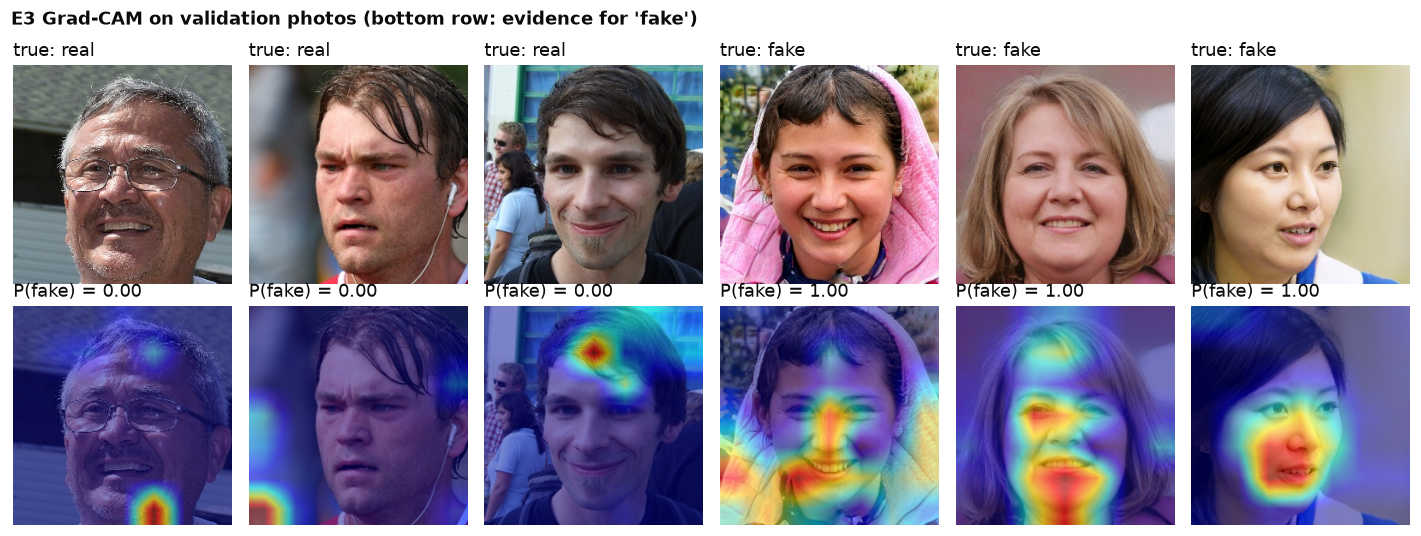

In [26]:
rng = random.Random(0)
v_reals = [p for p, t in val_ds.samples if t == val_ds.class_to_idx["real"]]
v_fakes = [p for p, t in val_ds.samples if t == val_ds.class_to_idx["fake"]]
chosen = [(p, "real") for p in rng.sample(v_reals, 3)] + [(p, "fake") for p in rng.sample(v_fakes, 3)]

e3_model, e3_cfg = load_checkpoint(checkpoint(EXPERIMENTS["E3"]), DEVICE)
explainer = Explainer(e3_model, e3_cfg["data"]["image_size"], DEVICE)

fig, axes = plt.subplots(2, 6, figsize=(13, 5))
for i, (path, truth) in enumerate(chosen):
    img = Image.open(path)
    prob, overlay = explainer(img)
    axes[0, i].imshow(img); axes[0, i].set_title(f"true: {truth}", fontweight="normal")
    axes[1, i].imshow(overlay); axes[1, i].set_title(f"P(fake) = {prob:.2f}", fontweight="normal")
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("E3 Grad-CAM on validation photos (bottom row: evidence for 'fake')", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

For fake faces the evidence concentrates on the **centre of the face: nose, mouth, teeth and chin**, where
StyleGAN's texture and blending artefacts are most common. The model is looking at the face, not at the
background or the photo border, which is reassuring for deployment.

## 11. Choosing a decision threshold for KYC (FAR vs. FRR)

The default rule flags a photo as fake when P(fake) ≥ 0.5. A bank can move this threshold:
- **Lower threshold** → more photos flagged → fewer fakes slip through (lower FAR), more genuine customers sent to
  manual review (higher FRR).
- **Higher threshold** → the opposite.

Using E3's scores on the live validation sample:

,far,frr,accuracy
threshold,,,
0.050000,0.40%,1.79%,98.90%
0.100000,0.40%,1.00%,99.30%
0.200000,0.60%,0.20%,99.60%
0.300000,1.20%,0.20%,99.30%
0.500000,2.41%,0.20%,98.70%
0.700000,3.21%,0.20%,98.30%
0.900000,4.82%,0.00%,97.60%


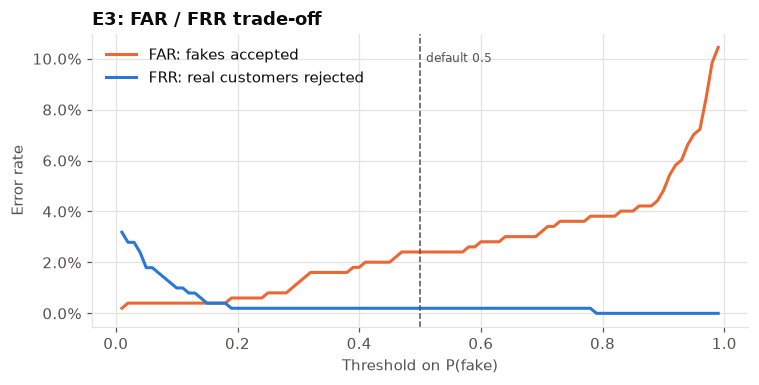

In [27]:
probs, y = live_probs["E3"]
thresholds = [0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9]
rows = [{"threshold": t} | {k: compute_metrics(y, probs, t)[k] for k in ("far", "frr", "accuracy")} for t in thresholds]
tradeoff = pd.DataFrame(rows).set_index("threshold")
display(tradeoff.style.format("{:.2%}"))

grid = np.linspace(0.01, 0.99, 99)
far = [compute_metrics(y, probs, t)["far"] for t in grid]
frr = [compute_metrics(y, probs, t)["frr"] for t in grid]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(grid, far, color=COLOURS[1], linewidth=2, label="FAR: fakes accepted")
ax.plot(grid, frr, color=COLOURS[0], linewidth=2, label="FRR: real customers rejected")
ax.axvline(0.5, color=INK_2, linewidth=1, linestyle="--"); ax.text(0.51, ax.get_ylim()[1] * 0.9, "default 0.5", color=INK_2, fontsize=8)
ax.set_xlabel("Threshold on P(fake)"); ax.set_ylabel("Error rate")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=1))
ax.set_title("E3: FAR / FRR trade-off"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

In KYC, accepting a synthetic identity is usually far more costly than asking a genuine customer for a second
check, so a bank would typically choose a threshold **below 0.5**: it lowers FAR at the cost of sending a few more
genuine customers to manual review. The exact threshold is a business decision, ideally set on validation data
from the bank's own onboarding channel.

## 12. Final test-set evaluation

The test set (20,000 images) was not used for any decision above. It was scored **once**, at the end, for the
final models (about 2 minutes per model). The saved results (`<exp>/eval_test.csv`) are loaded here, so this
section doesn't recompute anything. `RUN_TEST_EVAL = True` would only score models that have no saved result.

In [28]:
from deepfake_kyc import evaluate

FINAL = ["E1", "E2", "E3", "E4", "E5", "E6"]
rows = []
for exp in FINAL:
    name = EXPERIMENTS[exp]
    csv_path = OUTPUTS / name / "eval_test.csv"
    if RUN_TEST_EVAL and not csv_path.exists():
        evaluate.main(["--checkpoint", str(checkpoint(name)), "--split", "test"])
    for folder in (OUTPUTS / name, RESULTS / name):
        if (folder / "eval_test.csv").exists():
            r = pd.read_csv(folder / "eval_test.csv").query("condition == 'clean'").iloc[0]
            hist = pd.read_csv(run_dir(name) / "history.csv")
            val_acc = hist.loc[hist["val_loss"].idxmin(), "val_accuracy"]
            rows.append({"experiment": exp} | {k: r[k] for k in ("accuracy", "f1", "roc_auc", "far", "frr")}
                        | {"val_accuracy": val_acc, "test_minus_val": r["accuracy"] - val_acc})
            break

if rows:
    test = pd.DataFrame(rows).set_index("experiment")
    display(test.style.format({"accuracy": "{:.2%}", "f1": "{:.4f}", "roc_auc": "{:.4f}", "far": "{:.2%}",
                               "frr": "{:.2%}", "val_accuracy": "{:.2%}", "test_minus_val": "{:+.2%}"}))
else:
    print("Test set not evaluated yet. Set RUN_TEST_EVAL = True (once, at the end of the project).")

,accuracy,f1,roc_auc,far,frr,val_accuracy,test_minus_val
experiment,,,,,,,
E1,97.58%,0.9757,0.9972,2.61%,2.24%,97.52%,+0.06%
E2,78.24%,0.7817,0.8623,22.08%,21.44%,77.68%,+0.56%
E3,98.73%,0.9873,0.9994,1.82%,0.71%,98.89%,-0.16%
E4,98.00%,0.9798,0.9984,2.85%,1.15%,98.21%,-0.21%
E5,99.12%,0.9912,0.9995,0.97%,0.78%,99.17%,-0.05%
E6,98.28%,0.9827,0.9988,2.42%,1.02%,98.50%,-0.21%


**Reading the test results.** Every model scores within 0.6 points of its validation accuracy and the ranking is
unchanged (ResNet-50 > EfficientNet fine-tune > damage-trained > gradual > scratch CNN >> frozen). So choosing
epochs on the validation set did not over-fit it, and the validation-based comparisons above hold on unseen data.
For the main model E3, at the default 0.5 threshold, 1.8% of fakes were accepted (FAR) and 0.7% of real faces were
rejected (FRR).

## 13. Conclusions and limitations

**Conclusions**
1. A fine-tuned, ImageNet-pretrained EfficientNet-B0 (E3) detects StyleGAN faces with **98.7% accuracy on the held-out test set**
   (ROC-AUC 0.9994; 98.9% on validation), with a ~16 MB model that scores a photo in milliseconds.
2. **Fine-tuning is essential**: frozen pretrained features reach only ~78%. Gradual unfreezing gave no benefit, and
   a 6× larger ResNet-50 added only ~0.4 points (99.1% test).
3. **Data volume matters**: accuracy rises from ~66% (1k images) to ~97% (50k) and ~99% (100k).
4. **Robustness is the real deployment risk**: the standard model drops to near coin-flip on heavily blurred,
   noisy or low-resolution photos. **Training with simulated damage (E6)** raises average damaged-photo accuracy
   from ~72% to ~90% at almost no cost on clean photos.
5. **Grad-CAM** shows the model relies on the central face region (mouth, nose, teeth), where GAN artefacts appear.

**Limitations and next steps**
- **One generator only.** All fakes come from StyleGAN. Newer generators (diffusion models) and **face swaps** leave
  different traces; the model must be tested on them (an out-of-distribution test set) before any real use.
- **Simulated damage.** E6 was tested on the same damage types it trained on; real phone and screen captures may differ.
- **Dataset bias.** FFHQ photos are high quality and mostly frontal, unlike real ID selfies; performance across age,
  skin tone and lighting wasn't measured.
- **Single-image check.** A real KYC flow would combine this with liveness detection (video, challenge-response)
  and document checks rather than relying on one model.

## 14. How to reproduce

All outputs in this notebook are saved, so it can be read without running anything. To run it yourself:

1. Get the code: `git clone https://github.com/msondhi/UOT_SCS_3546_041_Deep-Learning.git` and
   `make setup` (creates `.venv` and installs the package and its dependencies).
2. Get the data (~2 GB): `make data` (needs a Kaggle API token in `~/.kaggle/access_token`), or download
   "140k Real and Fake Faces" from Kaggle and unzip it into `data/raw/`.
3. Get the trained models without retraining: download them from the GitHub release **models-v1** into
   `outputs/<experiment>/best.pt`, e.g.
   `gh release download models-v1 -R msondhi/UOT_SCS_3546_041_Deep-Learning -p 03_effnet_finetune.pt -O outputs/03_effnet_finetune/best.pt`.
   Per-epoch results are already in `results/`.
4. Open this notebook with the project's `.venv` kernel and run all cells (~1 minute). Set `RUN_TRAINING = True` to
   retrain every experiment instead (~20 hours on an Apple M5; faster on an NVIDIA GPU).

Individual steps from the command line: `make train CONFIG=configs/experiments/03_effnet_finetune.yaml`,
`make evaluate`, `make robustness`, `make explain`, and `make demo` (the Gradio web app).

## Appendix: complete source code

Every source file of the project, printed in full, so this notebook contains all the code used to produce the
results: the `deepfake_kyc` package, the experiment configs, the helper scripts, the demo app and the Makefile.

In [29]:
CODE_FILES = (
    sorted((ROOT / "src" / "deepfake_kyc").glob("*.py"))
    + [ROOT / "configs" / "base.yaml"] + sorted((ROOT / "configs" / "experiments").glob("*.yaml"))
    + sorted((ROOT / "scripts").glob("*.py")) + sorted((ROOT / "scripts").glob("*.sh"))
    + [ROOT / "app" / "app.py", ROOT / "Makefile"]
)
total = 0
for path in CODE_FILES:
    text = path.read_text()
    total += text.count("\n")
    print("=" * 100)
    print(f"# {path.relative_to(ROOT)}   ({text.count(chr(10))} lines)")
    print("=" * 100)
    print(text)
print(f"{len(CODE_FILES)} files, {total} lines in total")

# src/deepfake_kyc/__init__.py   (3 lines)
"""Detecting AI-generated faces in KYC identity verification."""

__version__ = "0.1.0"

# src/deepfake_kyc/config.py   (48 lines)
"""Load YAML experiment configs.

An experiment file can name a parent with ``base: <file>``; its values are merged
on top of the parent's. Command-line overrides use dotted keys, e.g.
``data.batch_size=32``.
"""

from __future__ import annotations

import copy
from collections.abc import Iterable
from pathlib import Path

import yaml


def _deep_merge(base: dict, override: dict) -> dict:
    merged = copy.deepcopy(base)
    for key, value in override.items():
        if isinstance(value, dict) and isinstance(merged.get(key), dict):
            merged[key] = _deep_merge(merged[key], value)
        else:
            merged[key] = value
    return merged


def apply_overrides(cfg: dict, overrides: Iterable[str]) -> dict:
    """Apply ``key.sub=value`` strings; values are parsed as YAML (numbers, bools, null)."""
    